## Oppgave 3c)

/tmp/ipykernel_220/4037968636.py:64: RuntimeWarning: overflow encountered in exp
  p_plus  = 1 / (1 + np.exp(-Beta_k*(V_l - V_r)) + np.exp(-Beta_k*(V_0 - V_r)))
/tmp/ipykernel_220/4037968636.py:65: RuntimeWarning: overflow encountered in exp
  p_minus = 1 / (1 + np.exp(-Beta_k*(V_r - V_l)) + np.exp(-Beta_k*(V_0 - V_l)))


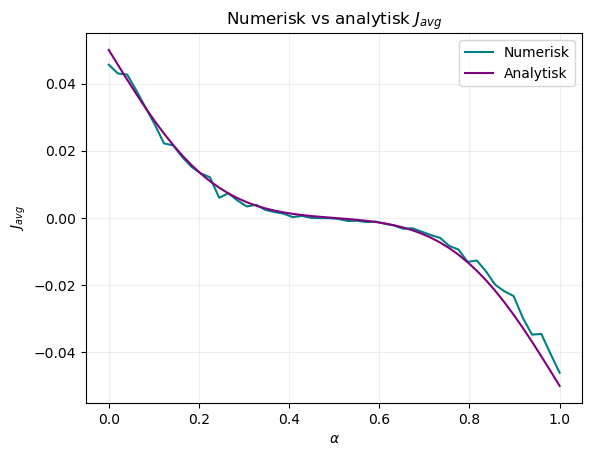

In [31]:
import numpy as np
import math
import matplotlib.pyplot as plt

h = 1
N_x = 100
P = 2 * N_x      
N_p = 12 * N_x
Beta_k = 1000
T_p = 500

np.random.seed(0)

alpha_vals = np.linspace(0, 1, 50)

def J_ana(alpha):

    sqr = np.sqrt(3 / T_p)
    a = ((alpha * N_x) / 2) * sqr
    b = (((1 - alpha) * N_x) / 2) * sqr
    return (N_x / (4 * T_p) ) * (math.erfc(a) - math.erfc(b))

    

def build_V1(alpha, N_x):
    peak = int(alpha * (N_x - 1))
    n = np.arange(N_x)
    V = np.zeros(N_x, dtype=float)

    left = (n <= peak)
    right = (n > peak)

    V[left]  = n[left] / max(peak, 1)
    V[right] = (N_x - 1 - n[right]) / max((N_x - 1 - peak), 1)

    return np.concatenate([V, V])

V2 = np.zeros(P)

J_num = np.zeros_like(alpha_vals, dtype=float)
J_analytical = np.zeros_like(alpha_vals, dtype=float)


for i, alpha in enumerate(alpha_vals):

    V1 = build_V1(alpha, N_x)

    x = np.array(int(N_p / 2) * [0, N_x], dtype=int) 

    J_sum = 0

    for j in range(2 * T_p):
        
        if (j < T_p):
            V = V2

        else:
            V = V1
            
        V_l = V[(x - 1) % P]
        V_0 = V[x]
        V_r = V[(x + 1) % P]

        p_plus  = 1 / (1 + np.exp(-Beta_k*(V_l - V_r)) + np.exp(-Beta_k*(V_0 - V_r)))
        p_minus = 1 / (1 + np.exp(-Beta_k*(V_r - V_l)) + np.exp(-Beta_k*(V_0 - V_l)))

        r = np.random.rand(N_p)
    
        pos = np.zeros_like(x) # tomt array med posisjon 0
        pos[r < p_minus] = -1
        pos[r > 1 - p_plus] = +1

        n_plus  = np.sum(pos == 1) # teller hvor mange partikler som gikk til høyre
        n_minus = np.sum(pos == -1) # teller hvor mange partikler som gikk til venstre
        J_t = (n_plus - n_minus) / N_p  # current J[i]

        J_sum += J_t
        x = (x + pos) % P  # periodisk randbettingelse
        

    J_num[i] = J_sum / (2 * T_p)

for i, alpha in enumerate(alpha_vals):
    J_analytical[i] = J_ana(alpha)
    
plt.plot(alpha_vals, J_num, label="Numerisk", color = "teal")
plt.plot(alpha_vals, J_analytical, label="Analytisk", color = "purple")
plt.grid(alpha=0.2)
plt.xlabel(r"$\alpha$")
plt.ylabel("$J_{avg}$")
plt.title("Numerisk vs analytisk $J_{avg}$")
plt.legend()
plt.show()

##### Kommentar til koden:

Plottet viser at den numeriske og analytiske løsningen av $J_{avg}$ er svært like. For  $\alpha < 0.5$ gir det positv strømning, mens høye verdier, $\alpha > 0.5$, gir negativ strømning. Både den analytsiske og den numeriske løsningen gir $J_{avg} = 0$ ved $\alpha \approx 0.5$. Her er sagtannspotensialet symmetrisk og sannsynligheten or å bevege seg mot høyre eller venstre blir dermed lik og kansellerer hverandre. En netto strøm oppstår altså kun ved asymmetrisk potensial. Plottingen av $J_{avg}$ som funskjon av $\alpha$ viser tydelig at retningen på strømmen kontrolleres av forskyvningen gitt av $\alpha$. Avviket mellom den numeriske og analytsiek løsningen øker når $\alpha$ går mot 0 og 1, men samsvarer godt rundt $\alpha \approx 0.5$. Forskjellen mellom den numeriske og analytiske løsningen kan visualiseres ved å plotte absolutt differanse.

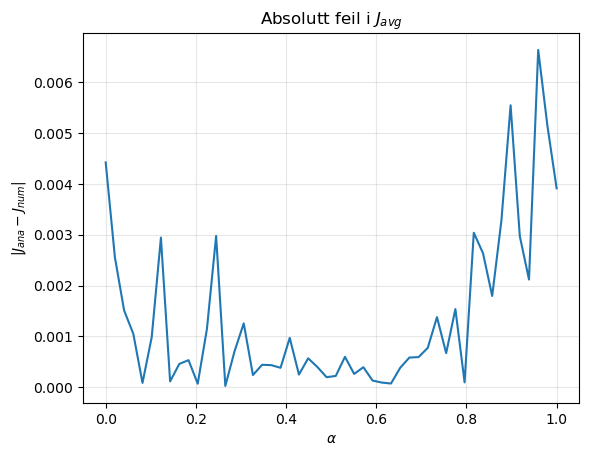

In [32]:
diff = J_analytical - J_num

abs_diff = np.abs(diff)

plt.figure()
plt.plot(alpha_vals, abs_diff)
plt.xlabel(r"$\alpha$")
plt.ylabel(r"$| J_{ana} - J_{num}| $")
plt.title("Absolutt feil i $J_{avg}$")
plt.grid(alpha=0.3)
plt.show()

Plottet viser som tidligere nevnt at løsningene samsvarer best rundt $\alpha \approx 0.5$, og  at avvikene øker når $\alpha$ går mot 0 og 1. I start og sluttverdiene for $\alpha$ blir sagtanpotensialet svært asymmetrisk. Fysisk vil det tilsi at partiklene nesten alltid vil falle mot en bestemt retning. Dermed vil strømmen domineres av noen få hopp. Dette kan bidra til små numeriske forskjeller som gir store avvik for $J_{avg}$. 

Dersom verdiene i eksponentialfunksjonen "np.exp()" blir for store, resulterer det i en "RuntimeWarning" og overflow. Det vil si at verdiene er for store for å passe valgt datatype. Standarden til python for float er 64-bit [NumPy – Basic data types](https://numpy.org/doc/stable/user/basics.types.html). En enkel løsning er dermed å endre til en datatype som klarer å håndtere større tall. Det finnes innebygde funksjoner i numpy som kan konvertere til eksempelvis 128-bit. Ved konvertering av datatype vil eksponentialfunksjonen klare å ta inn større verdier uten å få feilmeldinger. Eksponentialfunksjonen for $p_{plus}$ og $p_{minus}$ tar inn potensialert i tillegg til $\beta k$. Siden $\beta k = 1000 $ allerede er en kjent verdi vil det være enkelt å bytte datatype på denne variabelen. Testing av koden med endret dataype gir nå ingen feilmeldinger.

In [17]:
Beta_k = 1000

Beta_k_overflow = np.float128(Beta_k)

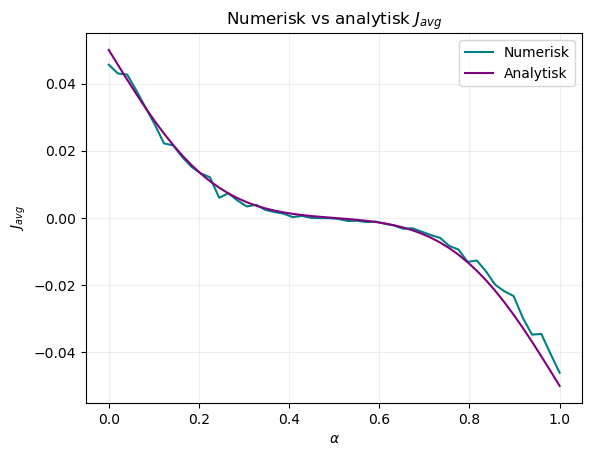

In [33]:
import numpy as np
import math
import matplotlib.pyplot as plt

h = 1
N_x = 100
P = 2 * N_x      
N_p = 12 * N_x
Beta_k = 1000
T_p = 500

np.random.seed(0)

alpha_vals = np.linspace(0, 1, 50)

Beta_k_overflow = np.float128(Beta_k)

def J_ana(alpha):

    sqr = np.sqrt(3 / T_p)
    a = ((alpha * N_x) / 2) * sqr
    b = (((1 - alpha) * N_x) / 2) * sqr
    return (N_x / (4 * T_p) ) * (math.erfc(a) - math.erfc(b))

    

def build_V1(alpha, N_x):
    peak = int(alpha * (N_x - 1))
    n = np.arange(N_x)
    V = np.zeros(N_x, dtype=float)

    left = (n <= peak)
    right = (n > peak)

    V[left]  = n[left] / max(peak, 1)
    V[right] = (N_x - 1 - n[right]) / max((N_x - 1 - peak), 1)

    return np.concatenate([V, V])

V2 = np.zeros(P)

J_num = np.zeros_like(alpha_vals, dtype=float)
J_analytical = np.zeros_like(alpha_vals, dtype=float)


for i, alpha in enumerate(alpha_vals):

    V1 = build_V1(alpha, N_x)

    x = np.array(int(N_p / 2) * [0, N_x], dtype=int) 

    J_sum = 0

    for j in range(2 * T_p):
        
        if (j < T_p):
            V = V2

        else:
            V = V1
            
        V_l = V[(x - 1) % P]
        V_0 = V[x]
        V_r = V[(x + 1) % P]

        p_plus  = 1 / (1 + np.exp(-Beta_k_overflow*(V_l - V_r)) + np.exp(-Beta_k_overflow*(V_0 - V_r)))
        p_minus = 1 / (1 + np.exp(-Beta_k_overflow*(V_r - V_l)) + np.exp(-Beta_k_overflow*(V_0 - V_l)))

        r = np.random.rand(N_p)
    
        pos = np.zeros_like(x) # tomt array med posisjon 0
        pos[r < p_minus] = -1
        pos[r > 1 - p_plus] = +1

        n_plus  = np.sum(pos == 1) # teller hvor mange partikler som gikk til høyre
        n_minus = np.sum(pos == -1) # teller hvor mange partikler som gikk til venstre
        J_t = (n_plus - n_minus) / N_p  # current J[i]

        J_sum += J_t
        x = (x + pos) % P  # periodisk randbettingelse
        

    J_num[i] = J_sum / (2 * T_p)

for i, alpha in enumerate(alpha_vals):
    J_analytical[i] = J_ana(alpha)
    
plt.plot(alpha_vals, J_num, label="Numerisk", color = "teal")
plt.plot(alpha_vals, J_analytical, label="Analytisk", color = "purple")
plt.grid(alpha=0.2)
plt.xlabel(r"$\alpha$")
plt.ylabel("$J_{avg}$")
plt.title("Numerisk vs analytisk $J_{avg}$")
plt.legend()
plt.show()